# z008 - Drift con bines (PSI)

**Idea:** para cada variable se cortan los valores de un mes de referencia en 10 bines (deciles) y,
con **esos mismos cortes**, se mira cómo se reparten los clientes de otro mes.
Si la variable no se movió, cada bin sigue teniendo ~10%.

**PSI** (Population Stability Index) resume el movimiento en un número:
< 0,1 estable · 0,1-0,25 se movió algo · > 0,25 se movió mucho.

Comparaciones:
- **202104 → 202106**: nuestra validación (train → valid).
- **202106 → 202108**: el último mes de train → el mes que predecimos.

In [1]:
# --- 1. Librerías y datos ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../competencia_01.parquet")
no_usar = ["numero_de_cliente", "foto_mes", "clase_ternaria"]
cols = [c for c in df.columns if c not in no_usar]
print(len(cols), "variables")

152 variables


In [2]:
# --- 2. Función PSI ---
def bines(ref, otro, n_bines=10):
    # Cortes = deciles del mes de referencia (sin repetir: muchas variables tienen muchos ceros)
    r = ref.dropna().values
    cortes = np.unique(np.quantile(r, np.linspace(0, 1, n_bines + 1)[1:-1])) if len(r) else np.array([])

    def proporciones(x):
        nan = x.isna().values
        b = np.searchsorted(cortes, x.values[~nan], side="right")   # a qué bin cae cada valor
        cuenta = np.bincount(b, minlength=len(cortes) + 1)
        cuenta = np.append(cuenta, nan.sum())                      # los NaN van en un bin aparte
        return cuenta / len(x)

    return proporciones(ref), proporciones(otro)

def psi(ref, otro):
    p, q = bines(ref, otro)
    p, q = np.clip(p, 1e-4, None), np.clip(q, 1e-4, None)          # evitar log(0)
    return float(np.sum((q - p) * np.log(q / p)))

In [3]:
# --- 3. PSI de cada variable en las dos comparaciones ---
pares = {"202104→202106": (202104, 202106), "202106→202108": (202106, 202108)}
filas = []
for c in cols:
    fila = {"variable": c}
    for nombre, (m1, m2) in pares.items():
        fila[nombre] = round(psi(df.loc[df["foto_mes"] == m1, c], df.loc[df["foto_mes"] == m2, c]), 3)
    filas.append(fila)

tabla = pd.DataFrame(filas).sort_values("202106→202108", ascending=False).reset_index(drop=True)
tabla.to_csv("z008_psi.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")

def nivel(v):
    return "mucho (>0,25)" if v > 0.25 else ("algo (0,1-0,25)" if v > 0.1 else "estable (<0,1)")
for nombre in pares:
    print(nombre, tabla[nombre].map(nivel).value_counts().to_dict())
tabla.head(25)

202104→202106 {'estable (<0,1)': 148, 'algo (0,1-0,25)': 2, 'mucho (>0,25)': 2}
202106→202108 {'estable (<0,1)': 149, 'algo (0,1-0,25)': 3}


,variable,202104→202106,202106→202108
0,cpayroll_trx,0.237,0.228
1,Visa_mpagado,0.000,0.185
2,mpayroll,0.214,0.116
3,Visa_Finiciomora,0.002,0.087
4,mcomisiones_otras,0.006,0.051
5,mcomisiones,0.006,0.050
6,mrentabilidad,0.010,0.038
7,mpasivos_margen,0.002,0.033
8,Master_Fvencimiento,0.031,0.026
9,Visa_Fvencimiento,0.019,0.015


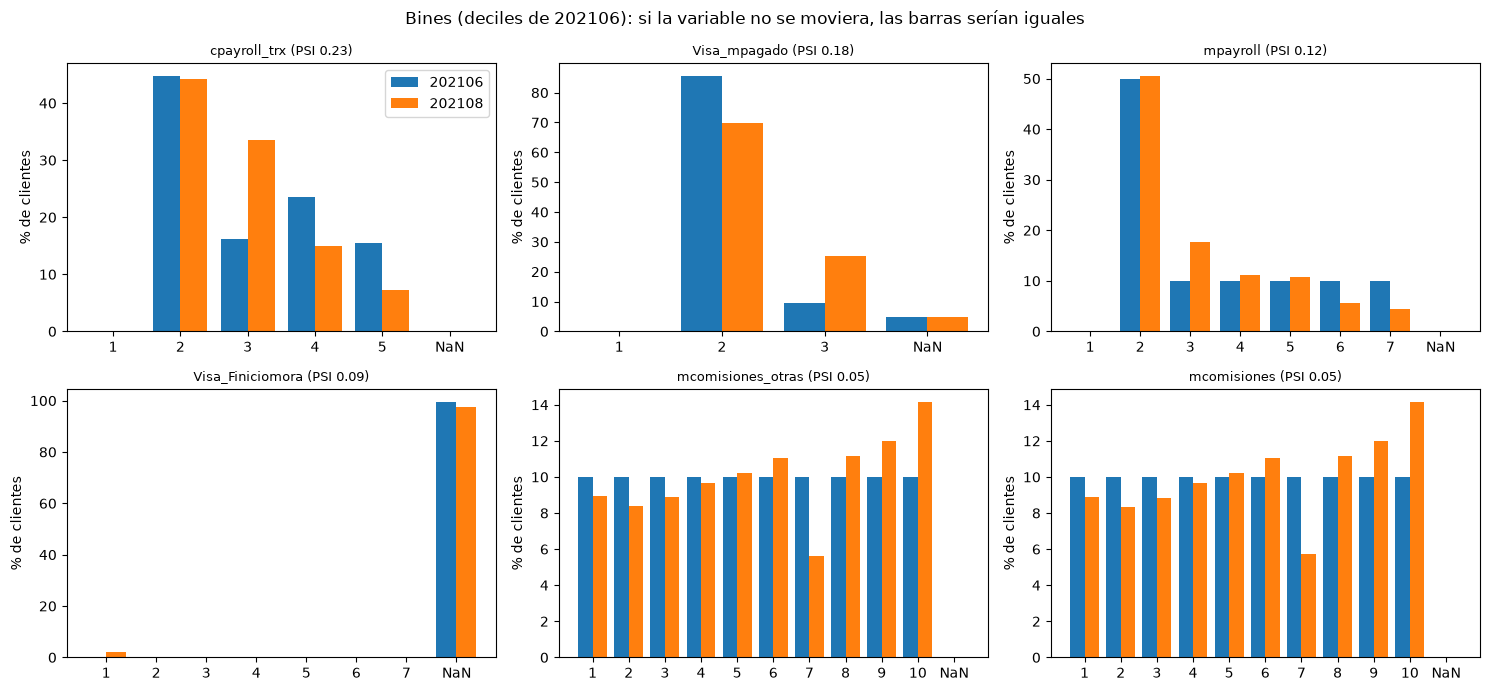

In [4]:
# --- 4. Gráfico de bines de las 6 variables que más se mueven (202106 → 202108) ---
peores = tabla["variable"].head(6)
fig, ejes = plt.subplots(2, 3, figsize=(15, 7))
for c, eje in zip(peores, ejes.ravel()):
    p, q = bines(df.loc[df["foto_mes"] == 202106, c], df.loc[df["foto_mes"] == 202108, c])
    x = np.arange(len(p))
    eje.bar(x - 0.2, p * 100, width=0.4, label="202106")
    eje.bar(x + 0.2, q * 100, width=0.4, label="202108")
    eje.set_xticks(x, [str(i + 1) for i in range(len(p) - 1)] + ["NaN"])
    eje.set_title(f"{c} (PSI {tabla.loc[tabla['variable'] == c, '202106→202108'].iloc[0]:.2f})", fontsize=9)
    eje.set_ylabel("% de clientes")
ejes[0, 0].legend()
plt.suptitle("Bines (deciles de 202106): si la variable no se moviera, las barras serían iguales")
plt.tight_layout()
plt.savefig("z008_bines.png", dpi=110, bbox_inches="tight")
plt.show()